## Figure 5

Training and validation curves

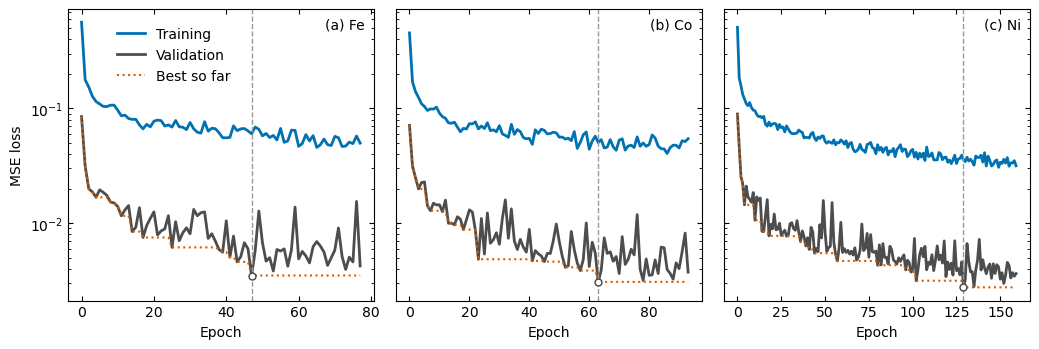

PNG: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure5_learning_curves.png
PDF: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure5_learning_curves.pdf


In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# Configuration
# ============================================================

figure_name = "Figure5_learning_curves"

systems = {
    "Fe": "Fe_d6",
    "Co": "Co_d7",
    "Ni": "Ni_d8",
}

panel_labels = {
    "Fe": "(a) Fe",
    "Co": "(b) Co",
    "Ni": "(c) Ni",
}

output_dpi = 300

show_best_so_far = True
show_best_epoch = True


# ============================================================
# Repository root
# ============================================================

def find_repository_root():
    current = Path.cwd().resolve()

    for candidate in [
        current,
        *current.parents,
    ]:
        if (
            (candidate / "src").is_dir()
            and
            (candidate / "configs").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root not found"
    )


repository_root = find_repository_root()

results_root = (
    repository_root
    / "results"
)

figure_directory = (
    repository_root
    / "figures"
)

figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Load histories
# ============================================================

histories = {}

for element, system in systems.items():

    history_file = (
        results_root
        / system
        / "training_history.csv"
    )

    if not history_file.is_file():
        raise FileNotFoundError(
            f"Training-history file not found:\n"
            f"{history_file}"
        )

    history = pd.read_csv(
        history_file
    )

    required_columns = {
        "epoch",
        "train_loss",
        "validation_loss",
    }

    missing_columns = (
        required_columns
        - set(history.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{system} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    epochs = history[
        "epoch"
    ].to_numpy(
        dtype=np.int64
    )

    train_loss = history[
        "train_loss"
    ].to_numpy(
        dtype=np.float64
    )

    validation_loss = history[
        "validation_loss"
    ].to_numpy(
        dtype=np.float64
    )

    if np.any(
        train_loss <= 0.0
    ):
        raise ValueError(
            f"{system}: train_loss contains "
            "non-positive values"
        )

    if np.any(
        validation_loss <= 0.0
    ):
        raise ValueError(
            f"{system}: validation_loss contains "
            "non-positive values"
        )

    sort_order = np.argsort(
        epochs
    )

    epochs = epochs[
        sort_order
    ]

    train_loss = train_loss[
        sort_order
    ]

    validation_loss = (
        validation_loss[
            sort_order
        ]
    )

    best_position = int(
        np.argmin(
            validation_loss
        )
    )

    best_epoch = int(
        epochs[
            best_position
        ]
    )

    best_validation_loss = float(
        validation_loss[
            best_position
        ]
    )

    if (
        "best_validation_loss_so_far"
        in history.columns
    ):
        best_so_far = history[
            "best_validation_loss_so_far"
        ].to_numpy(
            dtype=np.float64
        )[
            sort_order
        ]

    else:
        best_so_far = (
            np.minimum.accumulate(
                validation_loss
            )
        )

    histories[element] = {
        "epochs": epochs,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
        "best_so_far": best_so_far,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
    }


# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(10.5, 3.6),
    sharey=True,
)

colors = {
    "train": "#0072B2",
    "validation": "#4D4D4D",
    "best": "#D55E00",
}


# ============================================================
# Plot
# ============================================================

for ax, element in zip(
    axes,
    systems.keys()
):

    data = histories[
        element
    ]

    epochs = data[
        "epochs"
    ]

    train_loss = data[
        "train_loss"
    ]

    validation_loss = data[
        "validation_loss"
    ]

    best_so_far = data[
        "best_so_far"
    ]

    best_epoch = data[
        "best_epoch"
    ]

    best_validation_loss = data[
        "best_validation_loss"
    ]

    # ------------------------
    # Training
    # ------------------------

    ax.plot(
        epochs,
        train_loss,
        lw=2,
        color=colors["train"],
        label="Training",
    )

    # ------------------------
    # Validation
    # ------------------------

    ax.plot(
        epochs,
        validation_loss,
        lw=2,
        color=colors["validation"],
        label="Validation",
    )

    # ------------------------
    # Best-so-far
    # ------------------------

    if show_best_so_far:
        ax.plot(
            epochs,
            best_so_far,
            lw=1.5,
            ls=":",
            color=colors["best"],
            label="Best so far",
        )

    # ------------------------
    # Best epoch
    # ------------------------

    if show_best_epoch:
        ax.axvline(
            best_epoch,
            color="#999999",
            lw=1.0,
            ls="--",
        )

        ax.scatter(
            [
                best_epoch
            ],
            [
                best_validation_loss
            ],
            s=25,
            facecolor="white",
            edgecolor="#444444",
            zorder=5,
        )

    ax.set_yscale(
        "log"
    )

    ax.tick_params(
        direction="in",
        which="both",
        top=True,
        right=True,
    )

    ax.set_xlabel(
        "Epoch"
    )

    ax.text(
        0.97,
        0.97,
        panel_labels[element],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
    )


# ============================================================
# Labels
# ============================================================

axes[0].set_ylabel(
    "MSE loss"
)

axes[0].legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0.12, 0.98),
)


# ============================================================
# Save
# ============================================================

png_file = (
    figure_directory
    / f"{figure_name}.png"
)

pdf_file = (
    figure_directory
    / f"{figure_name}.pdf"
)

plt.tight_layout()

plt.savefig(
    png_file,
    dpi=output_dpi,
    bbox_inches="tight",
)

plt.savefig(
    pdf_file,
    bbox_inches="tight",
)

plt.show()

print(
    "PNG:",
    png_file
)

print(
    "PDF:",
    pdf_file
)